<a href="https://colab.research.google.com/github/siddala2005-ship-it/aimlApnaColg/blob/main/housepricePridictionusing__linear_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import seaborn as sns

In [4]:
prediction=pd.read_csv("HousePricePrediction.csv")

In [5]:
prediction

,Id,MSSubClass,MSZoning,LotArea,LotConfig,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,BsmtFinSF2,TotalBsmtSF,SalePrice
0,0,60,RL,8450,Inside,1Fam,5,2003,2003,VinylSd,0.0,856.0,208500.0
1,1,20,RL,9600,FR2,1Fam,8,1976,1976,MetalSd,0.0,1262.0,181500.0
2,2,60,RL,11250,Inside,1Fam,5,2001,2002,VinylSd,0.0,920.0,223500.0
3,3,70,RL,9550,Corner,1Fam,5,1915,1970,Wd Sdng,0.0,756.0,140000.0
4,4,60,RL,14260,FR2,1Fam,5,2000,2000,VinylSd,0.0,1145.0,250000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2914,2914,160,RM,1936,Inside,Twnhs,7,1970,1970,CemntBd,0.0,546.0,NaN
2915,2915,160,RM,1894,Inside,TwnhsE,5,1970,1970,CemntBd,0.0,546.0,NaN
2916,2916,20,RL,20000,Inside,1Fam,7,1960,1996,VinylSd,0.0,1224.0,NaN
2917,2917,85,RL,10441,Inside,1Fam,5,1992,1992,HdBoard,0.0,912.0,NaN


<Axes: xlabel='YearBuilt', ylabel='SalePrice'>

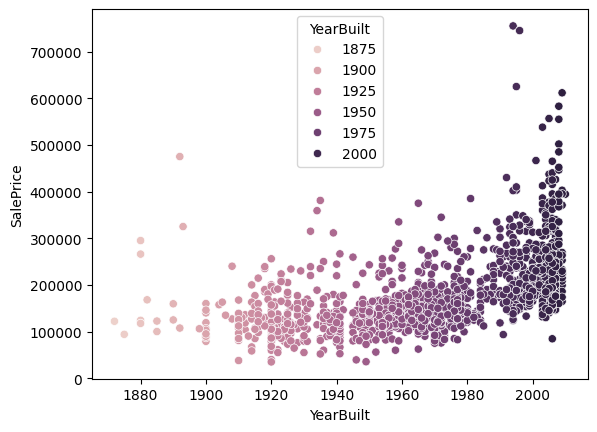

In [11]:
sns.scatterplot(x=prediction['YearBuilt'],y=prediction["SalePrice"],hue=prediction["YearBuilt"])

<Axes: xlabel='YearBuilt', ylabel='SalePrice'>

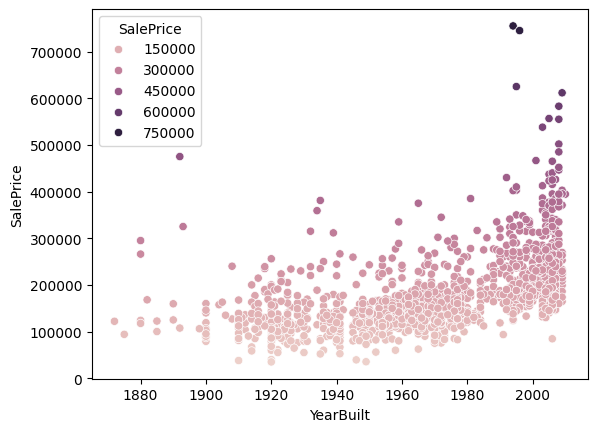

In [13]:
sns.scatterplot(x=prediction['YearBuilt'],y=prediction["SalePrice"],hue=prediction["SalePrice"])

In [19]:
x=prediction.drop(columns=["SalePrice","BsmtFinSF2","Id"])
##y=prediction(columns=["SalePrice"])
y=prediction["SalePrice"]

In [23]:
## used to check which colums to clean
x.isnull()
##counting the total false :for data,true/;for empty
x.isnull().sum()

,0
MSSubClass,0
MSZoning,4
LotArea,0
LotConfig,0
BldgType,0
OverallCond,0
YearBuilt,0
YearRemodAdd,0
Exterior1st,1
TotalBsmtSF,1


reloading data

In [35]:
x = prediction.drop(columns=["SalePrice", "BsmtFinSF2", "Id"])

In [36]:

##for numerical empty data we are filling it with its mean valur (.fillna is used to find empty and fill)
x["TotalBsmtSF"] = x["TotalBsmtSF"].fillna(x["TotalBsmtSF"].mean())
##caatogorial dat is filled with its mode value wher fill na is used to find the empty data
x["MSZoning"] = x["MSZoning"].fillna(x["MSZoning"].mode()[0])
x["Exterior1st"] = x["Exterior1st"].fillna(x["Exterior1st"].mode()[0])

In [37]:
x.head()

,MSSubClass,MSZoning,LotArea,LotConfig,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,TotalBsmtSF
0,60,RL,8450,Inside,1Fam,5,2003,2003,VinylSd,856.0
1,20,RL,9600,FR2,1Fam,8,1976,1976,MetalSd,1262.0
2,60,RL,11250,Inside,1Fam,5,2001,2002,VinylSd,920.0
3,70,RL,9550,Corner,1Fam,5,1915,1970,Wd Sdng,756.0
4,60,RL,14260,FR2,1Fam,5,2000,2000,VinylSd,1145.0


catagorial encoding:hot encoding

In [39]:
x=pd.get_dummies(x, columns=['MSZoning', 'LotConfig', 'BldgType', 'Exterior1st'])

In [40]:
x.head()

,MSSubClass,LotArea,OverallCond,YearBuilt,YearRemodAdd,TotalBsmtSF,MSZoning_C (all),MSZoning_FV,MSZoning_RH,MSZoning_RL,...,Exterior1st_CemntBd,Exterior1st_HdBoard,Exterior1st_ImStucc,Exterior1st_MetalSd,Exterior1st_Plywood,Exterior1st_Stone,Exterior1st_Stucco,Exterior1st_VinylSd,Exterior1st_Wd Sdng,Exterior1st_WdShing
0,60,8450,5,2003,2003,856.0,False,False,False,True,...,False,False,False,False,False,False,False,True,False,False
1,20,9600,8,1976,1976,1262.0,False,False,False,True,...,False,False,False,True,False,False,False,False,False,False
2,60,11250,5,2001,2002,920.0,False,False,False,True,...,False,False,False,False,False,False,False,True,False,False
3,70,9550,5,1915,1970,756.0,False,False,False,True,...,False,False,False,False,False,False,False,False,True,False
4,60,14260,5,2000,2000,1145.0,False,False,False,True,...,False,False,False,False,False,False,False,True,False,False


In [41]:
from sklearn.model_selection import train_test_split

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=0)

In [43]:
import numpy as np

# 1. Separate the records with known sale prices from those with missing sale prices (test set)
known_target_mask = y.notna()

x_labeled = x[known_target_mask]
y_labeled = y[known_target_mask]

# Keep the unlabelled data aside for final predictions later
x_unlabeled_test = x[~known_target_mask]

# 2. Perform train_test_split only on the labeled data
x_train, x_val, y_train, y_val = train_test_split(
    x_labeled,
    y_labeled,
    test_size=0.2,
    random_state=0
)

print(f"Training features shape: {x_train.shape}")
print(f"Validation features shape: {x_val.shape}")
print(f"Any missing values left in y_train? {y_train.isna().any()}")

Training features shape: (1168, 36)
Validation features shape: (292, 36)
Any missing values left in y_train? False


In [ ]:
from sklearn.model_selection import  RandomForestRegressor


In [46]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Initialize the models
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=0),
    "Random Forest": RandomForestRegressor(random_state=0, n_estimators=100)
}

# Train and evaluate each model
for name, model in models.items():
    # Fit model
    model.fit(x_train, y_train)

    # Predict on validation set
    predictions = model.predict(x_val)

    # Calculate metrics
    mae = mean_absolute_error(y_val, predictions)
    r2 = r2_score(y_val, predictions)

    print(f"=== {name} ===")
    print(f"Mean Absolute Error (MAE): ${mae:,.2f}")
    print(f"R-squared (R2) Score:     {r2:.4f}\n")

=== Linear Regression ===
Mean Absolute Error (MAE): $34,772.04
R-squared (R2) Score:     0.4388

=== Decision Tree ===
Mean Absolute Error (MAE): $33,875.39
R-squared (R2) Score:     0.5577

=== Random Forest ===
Mean Absolute Error (MAE): $24,983.69
R-squared (R2) Score:     0.7529



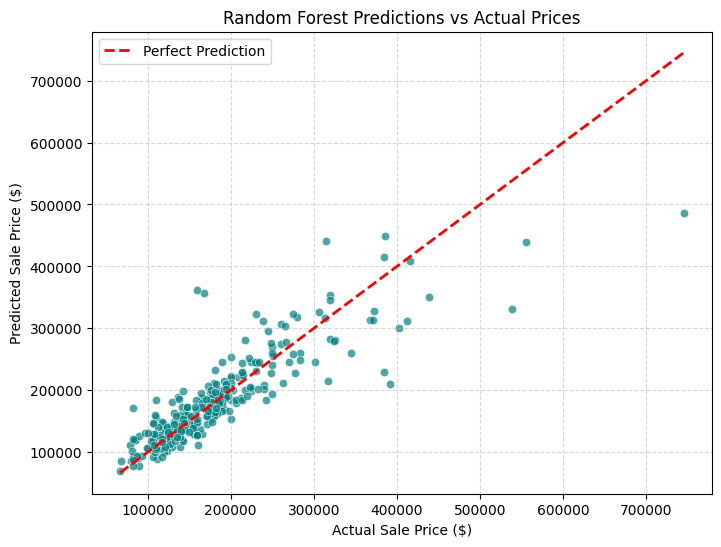

In [47]:
import matplotlib.pyplot as plt

# Get the Random Forest model explicitly
best_model = models["Random Forest"]
rf_predictions = best_model.predict(x_val)

# Create the scatter plot with a regression line reference
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_val, y=rf_predictions, alpha=0.7, color='teal')

# Plot the y = x line representing perfect predictions
plt.plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], color='red', linestyle='--', lw=2, label='Perfect Prediction')

plt.title('Random Forest Predictions vs Actual Prices')
plt.xlabel('Actual Sale Price ($)')
plt.ylabel('Predicted Sale Price ($)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

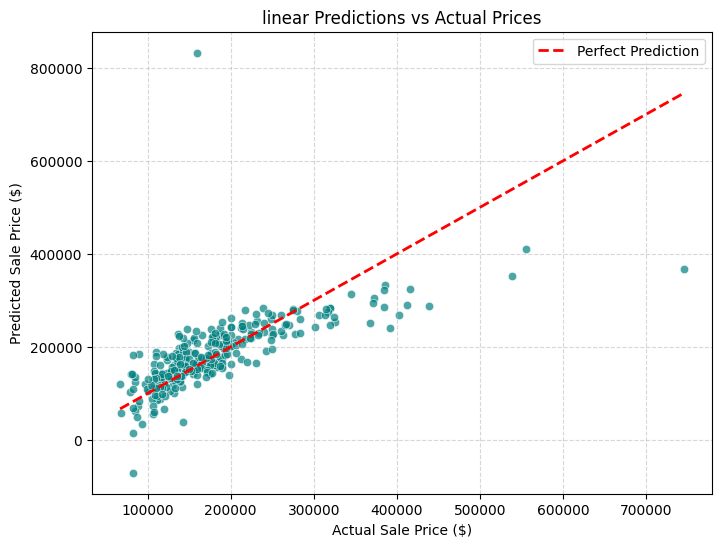

In [53]:
import matplotlib.pyplot as plt

# Get the Random Forest model explicitly
best_model = models["Linear Regression"]
rf_predictions = best_model.predict(x_val)

# Create the scatter plot with a regression line reference
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_val, y=rf_predictions, alpha=0.7, color='teal')

# Plot the y = x line representing perfect predictions
plt.plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], color='red', linestyle='--', lw=2, label='Perfect Prediction')

plt.title('linear Predictions vs Actual Prices')
plt.xlabel('Actual Sale Price ($)')
plt.ylabel('Predicted Sale Price ($)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

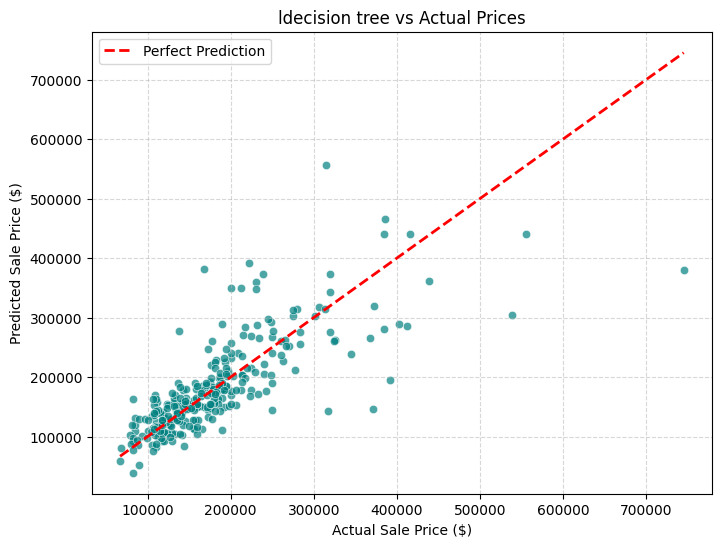

In [54]:
import matplotlib.pyplot as plt

# Get the Random Forest model explicitly
best_model = models["Decision Tree"]
rf_predictions = best_model.predict(x_val)

# Create the scatter plot with a regression line reference
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_val, y=rf_predictions, alpha=0.7, color='teal')

# Plot the y = x line representing perfect predictions
plt.plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], color='red', linestyle='--', lw=2, label='Perfect Prediction')

plt.title('decision tree vs Actual Prices')
plt.xlabel('Actual Sale Price ($)')
plt.ylabel('Predicted Sale Price ($)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [48]:
# Use our trained Random Forest model to predict prices for the unlabeled records
final_predictions = best_model.predict(x_unlabeled_test)

# Create a clean DataFrame to view the predicted prices along with original record indices
submission_df = pd.DataFrame({
    'Record_Index': x_unlabeled_test.index,
    'Predicted_SalePrice': final_predictions
})

# Show the first few predictions
submission_df.head(10)

,Record_Index,Predicted_SalePrice
0,1460,134869.00
1,1461,194617.50
2,1462,217484.10
3,1463,202332.25
4,1464,191347.56
5,1465,196338.50
6,1466,182305.00
7,1467,181689.84
8,1468,180036.02
9,1469,118773.65


In [49]:
# Use our trained Random Forest model to predict prices for the unlabeled records
final_predictions = best_model.predict(x_unlabeled_test)

# Create a clean DataFrame to view the predicted prices along with original record indices
submission_df = pd.DataFrame({
    'Record_Index': x_unlabeled_test.index,
    'Predicted_SalePrice': final_predictions
})

# Show the first few predictions
submission_df.head(10)

,Record_Index,Predicted_SalePrice
0,1460,134869.00
1,1461,194617.50
2,1462,217484.10
3,1463,202332.25
4,1464,191347.56
5,1465,196338.50
6,1466,182305.00
7,1467,181689.84
8,1468,180036.02
9,1469,118773.65


In [50]:
# Export the predicted prices to a CSV file
submission_df.to_csv('house_price_predictions.csv', index=False)
print("Saved successfully as 'house_price_predictions.csv'!")

Saved successfully as 'house_price_predictions.csv'!


In [51]:
# Export the predicted prices to a CSV file
submission_df.to_csv('house_price_predictions.csv', index=False)
print("Saved successfully as 'house_price_predictions.csv'!")

Saved successfully as 'house_price_predictions.csv'!
